Web Scraping (Loay)

In [6]:
import requests
import ast
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import csv


In [7]:
# Problem Encountered: HTTP Error 429, Too many requests
# Website blocks scraping and assumes we are a bot and immediately blocks us
# Use headers to trick website into thinking program is actually a browser, this effectively allows us to access the website and scrape it
url = "https://remoteok.com/remote-dev-jobs"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/112.0.0.0 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8",
}
# use beautiful soup to scrape the website
src = requests.get(url, headers=headers)
soup = BeautifulSoup(src.content)
soup

<!DOCTYPE html>
<html lang="en-US"><head><title>Just a moment...</title><meta content="text/html; charset=utf-8" http-equiv="Content-Type"/><meta content="IE=Edge" http-equiv="X-UA-Compatible"/><meta content="noindex,nofollow" name="robots"/><meta content="width=device-width,initial-scale=1" name="viewport"/><style>*{box-sizing:border-box;margin:0;padding:0}html{line-height:1.15;-webkit-text-size-adjust:100%;color:#313131;font-family:system-ui,-apple-system,BlinkMacSystemFont,Segoe UI,Roboto,Helvetica Neue,Arial,Noto Sans,sans-serif,Apple Color Emoji,Segoe UI Emoji,Segoe UI Symbol,Noto Color Emoji}body{display:flex;flex-direction:column;height:100vh;min-height:100vh}.main-content{margin:8rem auto;max-width:60rem;padding-left:1.5rem}@media (width <= 720px){.main-content{margin-top:4rem}}.h2{font-size:1.5rem;font-weight:500;line-height:2.25rem}@media (width <= 720px){.h2{font-size:1.25rem;line-height:1.5rem}}#challenge-error-text{background-image:url();background-repeat:no-repeat;backgro

In [8]:
listed_jobs = soup.find_all("tr", {"class":"job"})
print(listed_jobs)
# list of all the jobs on the website using calss named 'job'


[]


In [9]:
# Problem Encountered: Not all data loaded; must scroll to scrape it
# Install Selenium and use it to launch a Chrome instance of the website
# Script runs and scrolls to the end then all data is loaded and we can now scrape all/most 3ashan mankonsh kadabeen
# Store data in txt file to not run script every time, commented out for now
'''
from selenium import webdriver
from selenium.webdriver.common.by import By

path_to_file = "W:/Loay/Python Projects/ToolsProject/"

driver = webdriver.Chrome()
driver.maximize_window()

driver.get(url)

last_height = 0

while True:
    driver.execute_script('window.scrollBy(0, 5000)')
    time.sleep(4)

    new_height = driver.execute_script("return document.body.scrollHeight")

    if(new_height == last_height):
        break

    else:
        last_height = new_height

page_source = driver.page_source

f = open(path_to_file+"source.txt","w",encoding="utf-8")
f.write(page_source)
f.close()

driver.close()
'''

'\nfrom selenium import webdriver\nfrom selenium.webdriver.common.by import By\n\npath_to_file = "W:/Loay/Python Projects/ToolsProject/"\n\ndriver = webdriver.Chrome()\ndriver.maximize_window()\n\ndriver.get(url)\n\nlast_height = 0\n\nwhile True:\n    driver.execute_script(\'window.scrollBy(0, 5000)\')\n    time.sleep(4)\n\n    new_height = driver.execute_script("return document.body.scrollHeight")\n\n    if(new_height == last_height):\n        break\n\n    else:\n        last_height = new_height\n\npage_source = driver.page_source\n\nf = open(path_to_file+"source.txt","w",encoding="utf-8")\nf.write(page_source)\nf.close()\n\ndriver.close()\n'

In [ ]:
# Scrape html stored in txt file
import re
import numpy as np
from bs4 import BeautifulSoup

f = open(r"W:\Loay\Python Projects\ToolsProject\source.txt",'r',encoding='utf-8')
page_source = f.read()
f.close()
soup = BeautifulSoup(page_source)

# Get Job details and store in dictionary and convert it to csv file

listed_jobs = soup.find_all("tr", {"class":"job"})      # get listed jobs in tr with class name job
df_roles = []
df_organizations = []
df_locations = []
df_time_posted = []
df_tags = []
df_expected_salary = np.zeros(len(listed_jobs), dtype='object')
for i in range(0, len(listed_jobs)):
    role = listed_jobs[i].find("h2").text.strip()       # h2 tag stores role name
    organization = listed_jobs[i].find("h3").text.strip()       # h3 tag stores organization name
    html_location = listed_jobs[i].find_all("div", {"class": "location"})       # div stores list of location data in location class
    locations = []
    for j in html_location:
        if (str(j.contents)[2] == '💰'):        # this emoji indicates salary location tag, will store it in separate column
            salary_str = str(j.contents)
            salary_str = salary_str[4:-2]  # Clean string to get only salary part
            matches = re.findall(r'[0-9]{2,3}', salary_str)
            if len(matches) == 2:
                min_salary, max_salary = int(matches[0]), int(matches[1])
                avg_salary = min_salary + max_salary / 2.0
                df_expected_salary[i] = avg_salary
            elif len(matches) == 1:
                df_expected_salary[i] = int(matches[0])
            else:
                df_expected_salary[i] = None
            # some roles dont have a listed salary, most have it stored like ($min - $max) but some have only one value
        else:
            locations += j.contents

    locations = re.sub(r'<.*?>', r"", str(locations))
    html_time = listed_jobs[i].find("time")
    time_posted = re.sub(r'<.*?>', r'', (str(re.sub(r"[\t\n]", r"", str(html_time)))))
    html_tags = listed_jobs[i].find("td", {"class": "tags"}).find_all('h3')
    tags = [re.sub(r'<.*?>', r'', re.sub(r'[\s\t\n]', r'', str(i))) for i in html_tags]
    # regex used to remove unwanted characters and present data in list in a clean format
    df_roles.append(role)
    df_organizations.append(organization)
    df_locations.append(locations)
    df_time_posted.append(time_posted)
    df_tags.append(tags)
    # store record with its details

data = {'Role':df_roles, 'Organization':df_organizations, 'Locations':df_locations, 'Time_Posted':df_time_posted, 'Tags':df_tags, 'Expected_Salary (*1000$)':df_expected_salary}
# create dictionary and use it to create dataframe
# Scraped 1033 listed jobs

Importing Scraped Data and Data Cleaning (Abdelhamid + Ahmed)

In [11]:
# Reading the dataframe
import pandas as pd
df = pd.DataFrame(data)
df.to_csv('Scraped Data.csv')
df = pd.read_csv(r"W:\Loay\Python Projects\ToolsProject\Scraped Data.csv")
print(df)


      Unnamed: 0                                               Role  \
0              0                                      Web Developer   
1              1                  Senior React Full stack Developer   
2              2                           Administrative Executive   
3              3                                Full Stack Engineer   
4              4                  Internet of Things Technical Lead   
...          ...                                                ...   
1028        1028  Junior Full Stack Developer Complex Technical ...   
1029        1029   Sr Software Architect Engineer Node.js Meteor.js   
1030        1030                   Staff Software Engineer Accounts   
1031        1031                   Open Source Software Engineer Go   
1032        1032                           Senior Software Engineer   

              Organization                                          Locations  \
0                   Contra                    ['🌏 Worldwide', '⏰ C

In [12]:
df.head()

,Unnamed: 0,Role,Organization,Locations,Time_Posted,Tags,Expected_Salary (*1000$)
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']",22h,"['Other', 'Data', 'Consulting']",225.0
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...",1d,"['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']",4d,"['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']",15d,"['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],10d,"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0


In [13]:
print(df.isnull().sum())

Unnamed: 0                   0
Role                         0
Organization                 0
Locations                    0
Time_Posted                  0
Tags                         0
Expected_Salary (*1000$)    63
dtype: int64


In [14]:
mean = df["Expected_Salary (*1000$)"].mean()
df["Expected_Salary (*1000$)"].fillna(mean, inplace = True)
df

C:\Users\loaye\AppData\Local\Temp\ipykernel_42036\1693796763.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Expected_Salary (*1000$)"].fillna(mean, inplace = True)


,Unnamed: 0,Role,Organization,Locations,Time_Posted,Tags,Expected_Salary (*1000$)
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']",22h,"['Other', 'Data', 'Consulting']",225.0
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...",1d,"['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']",4d,"['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']",15d,"['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],10d,"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0
...,...,...,...,...,...,...,...
1028,1028,Junior Full Stack Developer Complex Technical ...,ConvertCalculator,['🌏 Worldwide'],6yr,"['JavaScript', 'Meteor', 'Junior', 'FullStack'...",120.0
1029,1029,Sr Software Architect Engineer Node.js Meteor.js,Peerlyst,"['🌏 Worldwide', 🇮🇳 India]",6yr,"['JavaScript', 'Meteor', 'Node', 'Engineer', '...",120.0
1030,1030,Staff Software Engineer Accounts,InVision,['🌏 Probably worldwide'],6yr,"['Golang', 'Engineer', 'Engineering']",122.5
1031,1031,Open Source Software Engineer Go,Datadog,['🌏 Probably worldwide'],6yr,"['Golang', 'Engineer', 'Go']",122.5


In [15]:
print(df.isnull().sum())

Unnamed: 0                  0
Role                        0
Organization                0
Locations                   0
Time_Posted                 0
Tags                        0
Expected_Salary (*1000$)    0
dtype: int64


In [16]:
df.head()

,Unnamed: 0,Role,Organization,Locations,Time_Posted,Tags,Expected_Salary (*1000$)
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']",22h,"['Other', 'Data', 'Consulting']",225.0
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...",1d,"['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']",4d,"['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']",15d,"['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],10d,"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0


In [17]:
# Problem Encountered: Time posted is not in a datetime format, need to convert it to a datetime format
def parse_duration(x):
    if pd.isna(x):
        return np.nan #NaN
    num = int(''.join(filter(str.isdigit, x)))  
    unit = ''.join(filter(str.isalpha, x)).lower()  
    
    if unit == 'h':
        return pd.Timedelta(hours=num)
    elif unit == 'd':
        return pd.Timedelta(days=num)
    elif unit == 'mo':
        return pd.Timedelta(minutes=num)
    elif unit == 'yr':  
        return pd.Timedelta(days=num * 365)  
    else:
        return np.nan 

df['Time_Posted_parsed'] = df['Time_Posted'].apply(parse_duration)


now = pd.Timestamp.now()


df['Actual_Time'] = now - df['Time_Posted_parsed']


df['Actual_Time'] = df['Actual_Time'].dt.date


df


,Unnamed: 0,Role,Organization,Locations,Time_Posted,Tags,Expected_Salary (*1000$),Time_Posted_parsed,Actual_Time
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']",22h,"['Other', 'Data', 'Consulting']",225.0,0 days 22:00:00,2025-04-30
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...",1d,"['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0,1 days 00:00:00,2025-04-30
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']",4d,"['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0,4 days 00:00:00,2025-04-27
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']",15d,"['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0,15 days 00:00:00,2025-04-16
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],10d,"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0,10 days 00:00:00,2025-04-21
...,...,...,...,...,...,...,...,...,...
1028,1028,Junior Full Stack Developer Complex Technical ...,ConvertCalculator,['🌏 Worldwide'],6yr,"['JavaScript', 'Meteor', 'Junior', 'FullStack'...",120.0,2190 days 00:00:00,2019-05-03
1029,1029,Sr Software Architect Engineer Node.js Meteor.js,Peerlyst,"['🌏 Worldwide', 🇮🇳 India]",6yr,"['JavaScript', 'Meteor', 'Node', 'Engineer', '...",120.0,2190 days 00:00:00,2019-05-03
1030,1030,Staff Software Engineer Accounts,InVision,['🌏 Probably worldwide'],6yr,"['Golang', 'Engineer', 'Engineering']",122.5,2190 days 00:00:00,2019-05-03
1031,1031,Open Source Software Engineer Go,Datadog,['🌏 Probably worldwide'],6yr,"['Golang', 'Engineer', 'Go']",122.5,2190 days 00:00:00,2019-05-03


In [18]:
df = df.drop("Time_Posted_parsed" , axis = 1)
df = df.drop("Time_Posted" , axis = 1)

In [19]:
df.rename(columns={'Actual_Time': 'Date_Posted'}, inplace=True)

df.head()

,Unnamed: 0,Role,Organization,Locations,Tags,Expected_Salary (*1000$),Date_Posted
0,0,Web Developer,Contra,"['🌏 Worldwide', '⏰ Contractor']","['Other', 'Data', 'Consulting']",225.0,2025-04-30
1,1,Senior React Full stack Developer,Lemon.io,"['🇪🇺 Europe', '💃 Latin America', 🇦🇺 Australia,...","['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0,2025-04-30
2,2,Administrative Executive,Prime Design & Build,"['💃 Latin America', '🌏 Worldwide']","['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0,2025-04-27
3,3,Full Stack Engineer,Stealth,"['🌏 Worldwide', '⏰ Contractor']","['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0,2025-04-16
4,4,Internet of Things Technical Lead,Sanctuary Computer,['🌏 Worldwide'],"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0,2025-04-21


In [20]:
#Remove unwanted characters from the Locations column
df['Locations'] = df['Locations'].apply(
    lambda x: '['+ re.sub(r'[^\w\s,]', '', str(x).lstrip('[').rstrip(']')) + ']'
)
df['Locations'] = df['Locations'].str.replace(r'\s+', ' ', regex=True).str.strip()


df.head()
df


,Unnamed: 0,Role,Organization,Locations,Tags,Expected_Salary (*1000$),Date_Posted
0,0,Web Developer,Contra,"[ Worldwide, Contractor]","['Other', 'Data', 'Consulting']",225.0,2025-04-30
1,1,Senior React Full stack Developer,Lemon.io,"[ Europe, Latin America, Australia, Canada, In...","['Engineer', 'Senior', 'JavaScript', 'FullStac...",175.0,2025-04-30
2,2,Administrative Executive,Prime Design & Build,"[ Latin America, Worldwide]","['SysAdmin', 'Design', 'Executive', 'Admin', '...",35.0,2025-04-27
3,3,Full Stack Engineer,Stealth,"[ Worldwide, Contractor]","['Pyton', 'Django', 'JavaScript', 'React', 'Fu...",150.0,2025-04-16
4,4,Internet of Things Technical Lead,Sanctuary Computer,[ Worldwide],"['ReactNative', 'Flutter', 'Android', 'Kotlin'...",190.0,2025-04-21
...,...,...,...,...,...,...,...
1028,1028,Junior Full Stack Developer Complex Technical ...,ConvertCalculator,[ Worldwide],"['JavaScript', 'Meteor', 'Junior', 'FullStack'...",120.0,2019-05-03
1029,1029,Sr Software Architect Engineer Node.js Meteor.js,Peerlyst,"[ Worldwide, India]","['JavaScript', 'Meteor', 'Node', 'Engineer', '...",120.0,2019-05-03
1030,1030,Staff Software Engineer Accounts,InVision,[ Probably worldwide],"['Golang', 'Engineer', 'Engineering']",122.5,2019-05-03
1031,1031,Open Source Software Engineer Go,Datadog,[ Probably worldwide],"['Golang', 'Engineer', 'Go']",122.5,2019-05-03


In [21]:
print(df.duplicated().sum())

0


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1033 entries, 0 to 1032
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                1033 non-null   int64  
 1   Role                      1033 non-null   object 
 2   Organization              1033 non-null   object 
 3   Locations                 1033 non-null   object 
 4   Tags                      1033 non-null   object 
 5   Expected_Salary (*1000$)  1033 non-null   float64
 6   Date_Posted               1033 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 56.6+ KB


In [23]:
df['Role'].unique()

array(['Web Developer', 'Senior React Full stack Developer',
       'Administrative Executive', 'Full Stack Engineer',
       'Internet of Things Technical Lead', 'Senior Software Engineer',
       'Javascript Fullstack Engineer Senior',
       'Full stack Ruby on Rails engineer Earn equity',
       'Full Stack Developer', 'Senior Mobile Developer',
       'Full Stack Web Developer',
       'Senior PHP Laravel Developer Full Stack', 'spoke person',
       'Senior Data Engineer', 'Sr Software Developer PHP MySQL',
       'React Native Developer', 'Intermediate Angular Developer',
       'Senior Software Engineer Backend', 'Developer',
       'Security & Risk Engineer US based', 'Full Stack React Engineer',
       'Front End lead developer', 'Backend Engineer',
       'Wordpress Developer', 'Software Engineer Backend',
       'Technical Support Engineer Developer', 'Senior Back End Wizard',
       'Principal Software Engineer', 'Product Marketing Manager',
       'Full stack Engineer PHP

In [24]:
df['Role'].nunique()

406

In [25]:
df['Role'].value_counts()

Role
Senior Software Engineer                         131
Software Engineer                                 52
Full Stack Developer                              29
Backend Developer                                 25
Senior Go Developer                               23
                                                ... 
Product Marketing Manager                          1
Lead Backend Developer                             1
Mid Senior Full Stack Ruby on Rails Developer      1
Senior Electron Developer                          1
Senior React Full stack Developer                  1
Name: count, Length: 406, dtype: int64

In [26]:
import ast
# Tags column is not in a list format, need to convert it to a list format
def safe_parse(x):
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]  
    return [x]

df['Tags'] = df['Tags'].apply(safe_parse)


In [27]:
# separates every single tag in the array 
print(df.explode('Tags'))


      Unnamed: 0                               Role Organization  \
0              0                      Web Developer       Contra   
0              0                      Web Developer       Contra   
0              0                      Web Developer       Contra   
1              1  Senior React Full stack Developer     Lemon.io   
1              1  Senior React Full stack Developer     Lemon.io   
...          ...                                ...          ...   
1032        1032           Senior Software Engineer      Netdata   
1032        1032           Senior Software Engineer      Netdata   
1032        1032           Senior Software Engineer      Netdata   
1032        1032           Senior Software Engineer      Netdata   
1032        1032           Senior Software Engineer      Netdata   

                                              Locations         Tags  \
0                              [ Worldwide, Contractor]        Other   
0                              [ Worldw

In [28]:
# Get all the unique tags in the Tags column
# df.explode('Tags') returns a dataframe with all the tags in the Tags column separated
df.explode('Tags')['Tags'].unique()

array(['Other', 'Data', 'Consulting', 'Engineer', 'Senior', 'JavaScript',
       'FullStack', 'React', 'FullTime', 'Ruby', 'Python', 'Node',
       'English', 'Postgres', 'Typescript', 'AWS', 'Startup', 'Next',
       'Remote', 'iOS', 'SysAdmin', 'Design', 'Executive', 'Admin',
       'VirtualAssistant', 'NonTech', 'Pyton', 'Django', 'ReactNative',
       'Flutter', 'Android', 'Kotlin', 'CSS', 'GraphQL', 'GCP', 'Azure',
       'Software', 'FrontEnd', 'Training', 'Technical', 'UX', 'Code',
       'Web', 'Scrum', 'DevOps', 'Cloud', 'Microsoft', 'Mobile',
       'Management', 'Lead', 'Healthcare', 'Engineering', 'Backend',
       'Shopify', 'Mobiledev', 'API', 'PHP', 'Laravel', 'Tailwind',
       'Marketing', 'Sales', 'CustomerSupport', 'DataEngineer', 'SQL',
       'Angular', 'RubyonRails', 'Elixir', 'PythonDjango', 'NodeExpress',
       'Aosp', 'Rest', 'Crypto', 'Ethereum', 'System', 'Security',
       'Developer', 'Growth', 'Financial', 'Rails', 'Reliability', 'SaaS',
       'Test', 'T

In [29]:
df.explode('Tags')['Tags'].nunique()


232

In [30]:
df.explode('Tags')['Tags'].value_counts()


Tags
Golang           515
Engineer         510
Senior           487
JavaScript       353
Backend          300
                ... 
Xamarin            1
Nginx              1
SmartContract      1
Bookkeeping        1
Math               1
Name: count, Length: 232, dtype: int64

In [31]:
# Rebuild locations column to be in a list format
def add_quotes_to_list_string(cell):
    if isinstance(cell, str):
        # Remove the brackets first
        cell = cell.strip('[]')
        # Split by comma
        items = [item.strip() for item in cell.split(',') if item.strip()]
        # Add quotes
        quoted_items = [f'"{item}"' for item in items]
        # Rebuild the string with brackets
        return '[' + ', '.join(quoted_items) + ']'
    else:
        return cell

df['Locations'] = df['Locations'].apply(add_quotes_to_list_string)


In [32]:
import ast

def safe_parse(x):
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return [x]  
    return [x]

df['Locations'] = df['Locations'].apply(safe_parse)

In [33]:
# separates every single tag in the array 
print(df.explode('Locations'))


      Unnamed: 0                                              Role  \
0              0                                     Web Developer   
0              0                                     Web Developer   
1              1                 Senior React Full stack Developer   
1              1                 Senior React Full stack Developer   
1              1                 Senior React Full stack Developer   
...          ...                                               ...   
1029        1029  Sr Software Architect Engineer Node.js Meteor.js   
1029        1029  Sr Software Architect Engineer Node.js Meteor.js   
1030        1030                  Staff Software Engineer Accounts   
1031        1031                  Open Source Software Engineer Go   
1032        1032                          Senior Software Engineer   

     Organization           Locations  \
0          Contra           Worldwide   
0          Contra          Contractor   
1        Lemon.io              Europ

In [34]:
df.explode('Locations')['Locations'].unique()


array(['Worldwide', 'Contractor', 'Europe', 'Latin America', 'Australia',
       'Canada', 'Indonesia', 'New Zealand', 'Papua New Guinea',
       'Philippines', 'United Kingdom', 'United States',
       'Probably worldwide', 'Part time', 'South Africa', 'Minneapolis',
       'MN', 'India', 'Mumbai', 'North America', 'Spain', 'Poland',
       'Brazil', 'Middle East', 'Germany', nan, 'Canada Open to us',
       'Contract', 'Europe not just EU', 'Africa',
       'Canada East Canada Time Zones', 'Toronto', 'Ontario Canada', 'PT',
       'MT', 'CT', 'ET', 'UTC6', 'UTC7', 'Asia', 'European Timezone',
       'Morocco', 'Denmark', 'Czechia', 'Singapore', 'Malaysia', 'China',
       'Hong Kong', 'ANYWHERE IN EUROPE', 'Russia', 'Taiwan', 'Thailand',
       'Bulgaria', 'Based in European timezone between UTC1 and UTC3',
       'Remote between UTC3 and UTC3', 'Europe UTC1 to UTC3',
       'UTC1 German Timezone',
       'Remote position Full time WesternEastern Europe European Time Zone UTC1 to 3 o

In [35]:
df.explode('Locations')['Locations'].nunique()


59

In [36]:
df.explode('Locations')['Locations'].value_counts()


Locations
Probably worldwide                                                                                    484
Worldwide                                                                                             284
United States                                                                                         104
Europe                                                                                                103
Canada                                                                                                 36
Latin America                                                                                          32
North America                                                                                          30
United Kingdom                                                                                         21
Poland                                                                                                  6
Contractor                          

In [37]:
df

,Unnamed: 0,Role,Organization,Locations,Tags,Expected_Salary (*1000$),Date_Posted
0,0,Web Developer,Contra,"[Worldwide, Contractor]","[Other, Data, Consulting]",225.0,2025-04-30
1,1,Senior React Full stack Developer,Lemon.io,"[Europe, Latin America, Australia, Canada, Ind...","[Engineer, Senior, JavaScript, FullStack, Reac...",175.0,2025-04-30
2,2,Administrative Executive,Prime Design & Build,"[Latin America, Worldwide]","[SysAdmin, Design, Executive, Admin, VirtualAs...",35.0,2025-04-27
3,3,Full Stack Engineer,Stealth,"[Worldwide, Contractor]","[Pyton, Django, JavaScript, React, FullStack, ...",150.0,2025-04-16
4,4,Internet of Things Technical Lead,Sanctuary Computer,[Worldwide],"[ReactNative, Flutter, Android, Kotlin, JavaSc...",190.0,2025-04-21
...,...,...,...,...,...,...,...
1028,1028,Junior Full Stack Developer Complex Technical ...,ConvertCalculator,[Worldwide],"[JavaScript, Meteor, Junior, FullStack, Custom...",120.0,2019-05-03
1029,1029,Sr Software Architect Engineer Node.js Meteor.js,Peerlyst,"[Worldwide, India]","[JavaScript, Meteor, Node, Engineer, Architect...",120.0,2019-05-03
1030,1030,Staff Software Engineer Accounts,InVision,[Probably worldwide],"[Golang, Engineer, Engineering]",122.5,2019-05-03
1031,1031,Open Source Software Engineer Go,Datadog,[Probably worldwide],"[Golang, Engineer, Go]",122.5,2019-05-03


In [38]:
df.drop(columns='Unnamed: 0', inplace=True)
df

,Role,Organization,Locations,Tags,Expected_Salary (*1000$),Date_Posted
0,Web Developer,Contra,"[Worldwide, Contractor]","[Other, Data, Consulting]",225.0,2025-04-30
1,Senior React Full stack Developer,Lemon.io,"[Europe, Latin America, Australia, Canada, Ind...","[Engineer, Senior, JavaScript, FullStack, Reac...",175.0,2025-04-30
2,Administrative Executive,Prime Design & Build,"[Latin America, Worldwide]","[SysAdmin, Design, Executive, Admin, VirtualAs...",35.0,2025-04-27
3,Full Stack Engineer,Stealth,"[Worldwide, Contractor]","[Pyton, Django, JavaScript, React, FullStack, ...",150.0,2025-04-16
4,Internet of Things Technical Lead,Sanctuary Computer,[Worldwide],"[ReactNative, Flutter, Android, Kotlin, JavaSc...",190.0,2025-04-21
...,...,...,...,...,...,...
1028,Junior Full Stack Developer Complex Technical ...,ConvertCalculator,[Worldwide],"[JavaScript, Meteor, Junior, FullStack, Custom...",120.0,2019-05-03
1029,Sr Software Architect Engineer Node.js Meteor.js,Peerlyst,"[Worldwide, India]","[JavaScript, Meteor, Node, Engineer, Architect...",120.0,2019-05-03
1030,Staff Software Engineer Accounts,InVision,[Probably worldwide],"[Golang, Engineer, Engineering]",122.5,2019-05-03
1031,Open Source Software Engineer Go,Datadog,[Probably worldwide],"[Golang, Engineer, Go]",122.5,2019-05-03


In [39]:
role_salary_df = df[['Role', 'Expected_Salary (*1000$)']]
print(role_salary_df.sample(10))

                                                  Role  \
950  Meteor developer for trouble shooting excessiv...   
317                           React Frontend Developer   
770                  Senior Software Engineer Frontend   
787                          Senior Go stack developer   
740                              Go Developer Engineer   
250                            Senior Golang Developer   
467                           Senior Software Engineer   
602               Go Engineer k6 Open Source developer   
482                               Senior Web Developer   
669                       Senior Software Engineer 100   

     Expected_Salary (*1000$)  
950                     125.0  
317                      80.0  
770                      92.5  
787                     125.0  
740                     122.5  
250                     125.0  
467                     190.0  
602                     122.5  
482                     170.0  
669                     125.0  


In [40]:
df.to_csv('Scraped Data.csv') # Update csv file with our formatted data, this same data will be stored in MongoDB
df['Organization'].value_counts()

Organization
Toptal                   25
Doximity                 21
X Team                   17
Vistas Recruitment       17
Spacemesh                14
                         ..
SpiderOak                 1
Remote-how                1
Form3 Financial Cloud     1
JDCLD Trading             1
Headway                   1
Name: count, Length: 538, dtype: int64

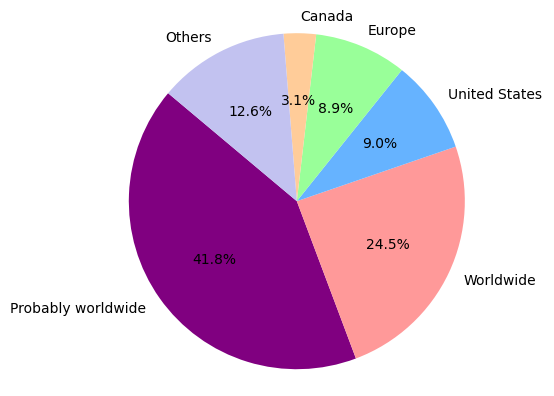

In [41]:
#geting the value counts of locations
locations_count = df.explode('Locations')['Locations'].value_counts()

#gets top 5 locations and their counts and put any thing else in others
sizes = locations_count.head().values
labels = locations_count.head().index.tolist()
#adding a category named "others" if there are more locations (more the first than 5)
if len(locations_count) > 5:
    others_count = locations_count[6:].sum()
    sizes = np.append(sizes, others_count)
    labels.append('Others')
colors = ['purple','#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0'][:len(labels)]
#pie chart
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=140)
plt.axis('equal')
plt.show()

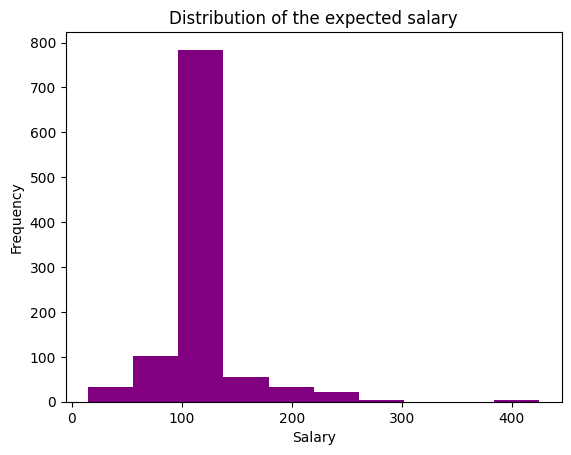

In [42]:
# Showing the distribution and variance of the salary
ax = plt.gca()
ax.hist(df['Expected_Salary (*1000$)'],color='purple')
plt.title('Distribution of the expected salary')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.show()

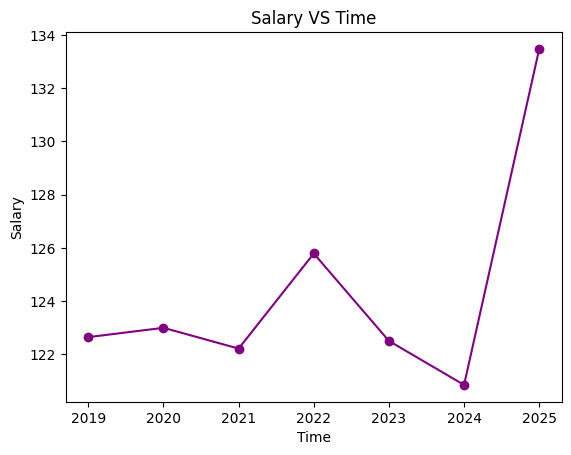

In [43]:
# Showing the correlation between the salary over the years
Year = pd.DatetimeIndex(df['Date_Posted']).year
mean_salary = df.groupby(Year)['Expected_Salary (*1000$)'].mean().reset_index()

plt.plot(mean_salary['Date_Posted'],mean_salary['Expected_Salary (*1000$)'],color='purple',marker='o')
plt.title('Salary VS Time')
plt.xlabel('Time')
plt.ylabel('Salary')
plt.show()


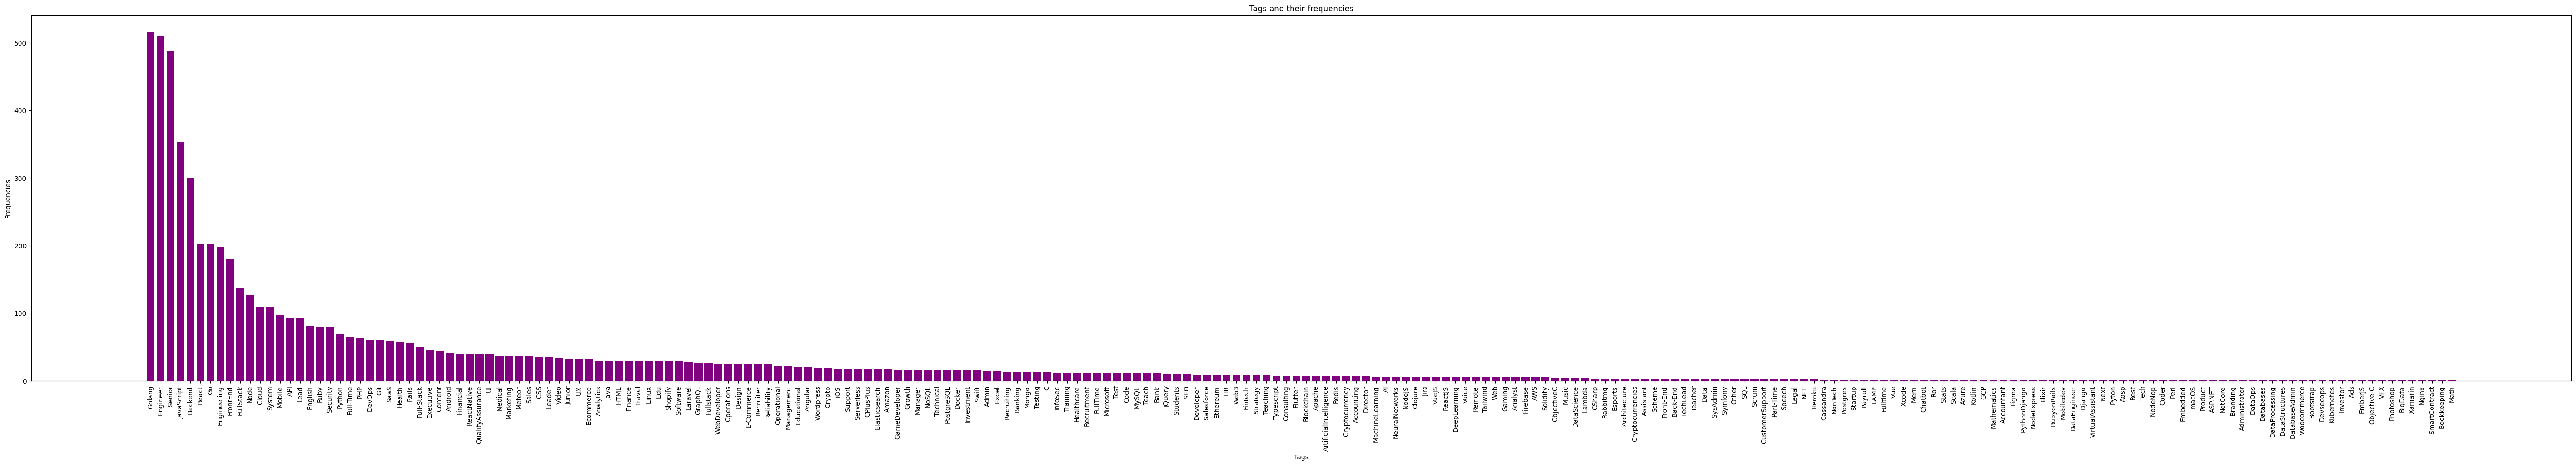

In [44]:
# Showing the frequency of the tags over the years
tag_count = df['Tags'].explode().value_counts().reset_index()

plt.figure(figsize=(69, 10))
plt.bar(tag_count['Tags'], tag_count['count'], color = 'purple')
plt.title('Tags and their frequencies')
plt.xlabel('Tags')
plt.ylabel('Frequencies')
plt.xticks(rotation=90)
plt.show()

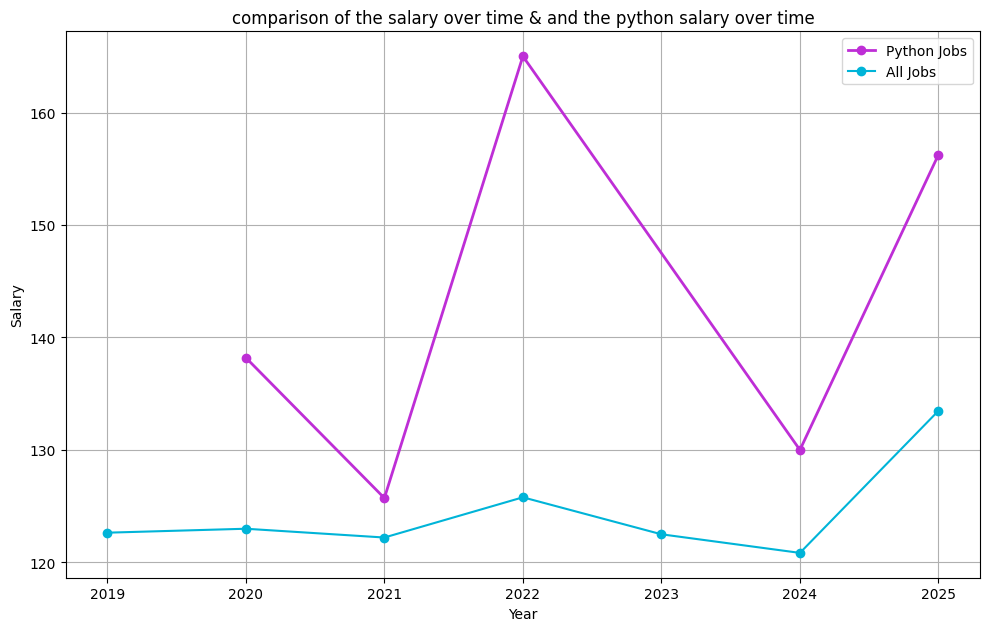

In [45]:
df['Year'] = pd.to_datetime(df['Date_Posted']).dt.year

#then filter the dataframe to only include rows with 'Python' tag
df_python = df[df['Tags'].apply(lambda x: 'Python' in x)]

#now group by the 'Year' column that exists in the filtered dataframe
mean_salaries_by_year = df_python.groupby('Year')['Expected_Salary (*1000$)'].mean().reset_index()

#create line plot to show trend over time
plt.figure(figsize=(10, 6))
plt.plot(mean_salaries_by_year['Year'], mean_salaries_by_year['Expected_Salary (*1000$)'],marker='o', color='#be2ed6', linewidth=2)
plt.ylabel('Mean Salary (in thousands)')
plt.grid(True)
plt.tight_layout()

Year = pd.DatetimeIndex(df['Date_Posted']).year
mean_salary = df.groupby(Year)['Expected_Salary (*1000$)'].mean().reset_index()

plt.plot(mean_salary['Date_Posted'],mean_salary['Expected_Salary (*1000$)'],color='#00b4d8',marker='o')
plt.title('comparison of the salary over time & and the python salary over time')
plt.xlabel('Year')
plt.ylabel('Salary')
plt.legend(['Python Jobs', 'All Jobs'])
plt.show()

Data Storage Using MongoDB (Loay)

In [46]:
'''
from pymongo import MongoClient
import datetime
client = MongoClient("mongodb://localhost:27017/")
mydb = client['RemoteOk']
for organ in df['Organization'].unique():
    while organ[-1] ==  '.':
        organ = organ[0:-1] # organization has a . at the end of its name causes error with driver
    col = mydb[organ]
    for job in df.index:
        d = datetime.datetime.strptime(str(df.loc[job, 'Date_Posted']), "%Y-%m-%d")
        if df.loc[job, 'Organization'] == organ:
            item = {
                "Role":df.loc[job, 'Role'],
                "Locations":df.loc[job, 'Locations'],
                "Tags":df.loc[job,'Tags'],
                "Expected_Salary in $1,000":df.loc[job, 'Expected_Salary (*1000$)'],
                "Date_posted":d
            }
            col.insert_one(item)
'''

'\nfrom pymongo import MongoClient\nimport datetime\nclient = MongoClient("mongodb://localhost:27017/")\nmydb = client[\'RemoteOk\']\nfor organ in df[\'Organization\'].unique():\n    while organ[-1] ==  \'.\':\n        organ = organ[0:-1] # organization has a . at the end of its name causes error with driver\n    col = mydb[organ]\n    for job in df.index:\n        d = datetime.datetime.strptime(str(df.loc[job, \'Date_Posted\']), "%Y-%m-%d")\n        if df.loc[job, \'Organization\'] == organ:\n            item = {\n                "Role":df.loc[job, \'Role\'],\n                "Locations":df.loc[job, \'Locations\'],\n                "Tags":df.loc[job,\'Tags\'],\n                "Expected_Salary in $1,000":df.loc[job, \'Expected_Salary (*1000$)\'],\n                "Date_posted":d\n            }\n            col.insert_one(item)\n'

Streamlit Bonus (Mohammed + Abdelmalek)

In [47]:
import plotly.express as px
import streamlit as st
st.header(" Data after cleaning")

st.dataframe(df)

col1, col2 = st.columns(2)
with col1:
    st.metric(label="Total rows",value = len(df))
with col2:
    st.metric(label="Total columns",value= len(df.columns))

st.header('Charts :')
# Distribution of locations using pie chart
pie = px.pie(
    values=sizes,
    names=labels,
    color_discrete_sequence=['purple', '#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0'],
    title='Distribution of Locations'
)
st.plotly_chart(pie)

# Distribution of expected salary using histogram 
hist = px.histogram(
    df,
    x='Expected_Salary (*1000$)',
    color_discrete_sequence=['#be2ed6'], 
    title='Distribution of the Expected Salary',
    labels={'Expected_Salary (*1000$)': 'Salary (in thousands $)'}
)
hist.update_layout(
    xaxis_title='Salary (in thousands $)',
    yaxis_title='Frequency',
    bargap=0.1, 
)
st.plotly_chart(hist)

# Salary mean over the years using line chart
line = px.line(
    mean_salary,
    x='Date_Posted', 
    y='Expected_Salary (*1000$)',
    title='Salary Trends Over Time',
    labels={
        'Date_Posted': 'Year',
        'Expected_Salary (*1000$)': 'Average Salary (in thousands $)'
    },
    markers=True 
)
line.update_traces(
    line_color='#be2ed6',
    line_width=2,
    marker=dict(
        size=8,
        color='#e8bcf0',
        line=dict(width=1, color='white')
    )
)
line.update_layout(
    xaxis_title='Year',
    yaxis_title='Average Salary (in thousands $)',
    hovermode='x unified' 
)
st.plotly_chart(line)
    
# frequancy of the tags by using bar chart
tag_count.columns = ['Tags', 'Count']
bar = px.bar(
    tag_count,
    x='Tags',
    y='Count',
    title='Tags and Their Frequencies',
    labels={'Count': 'Frequency', 'Tags': 'Tags'},
    color_discrete_sequence=['#be2ed6'] 
)
bar.update_layout(
    xaxis_title='Tags',
    yaxis_title='Frequency',
    xaxis_tickangle=-90, 
    height=600,
    width=1200, 
    margin=dict(l=20, r=20, t=60, b=200)
)
st.plotly_chart(bar, use_container_width=True)

2025-05-01 14:32:32.177 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-01 14:32:32.641 
  command:

    streamlit run C:\Users\loaye\AppData\Roaming\Python\Python313\site-packages\ipykernel_launcher.py [ARGUMENTS]
2025-05-01 14:32:32.642 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-01 14:32:32.654 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-01 14:32:32.656 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-01 14:32:32.658 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-01 14:32:32.658 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-01 14:32:32.659 Thre

DeltaGenerator()